# [Lab Session 2](otsu.ipynb)

In [56]:
import numpy as np
import matplotlib.pyplot as plt

**[Task 1.1.]()** Load the image:

In [57]:
imgf = plt.imread('data/NIH3T3/im/dna-0.png')

**[Task 1.2.]()** Quantify the image into 256 bins:

In [58]:
img8 = (imgf * 255).round().astype(np.uint8)

**[Task 1.3.]()** Compute the image histogram:

In [59]:
h = np.zeros(256)
for i in range(256): #nacheinander alle Helligkeiten durch 
    h[i]= np.sum(img8 == i ) #fragt bei jeem Pixel ob true zu der Helligkeit gehört, True = 1

print(h)
print(sum(h))
print(len(h))
print(h.sum() == img8.size) #Anzahl der Pixel mit einer Intensität Höhexbeite des Bildes, kein Pixel doppelt gezählt 
    

[0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 1.00000e+00 1.38400e+03 1.25478e+05 5.50322e+05 3.44173e+05 7.58140e+04
 2.48010e+04 1.36310e+04 9.13900e+03 7.39000e+03 6.74300e+03 6.93000e+03
 7.92500e+03 9.88700e+03 1.23170e+04 1.46320e+04 1.61230e+04 1.74000e+04
 1.75300e+04 1.67810e+04 1.49330e+04 1.31710e+04 1.09560e+04 8.97200e+03
 7.37900e+03 6.16300e+03 5.23700e+03 4.49100e+03 3.96200e+03 3.38200e+03
 2.84100e+03 2.50500e+03 2.06900e+03 1.77900e+03 1.39700e+03 1.19400e+03
 1.01200e+03 8.85000e+02 7.33000e+02 6.39000e+02 5.54000e+02 5.18000e+02
 4.19000e+02 3.71000e+02 3.02000e+02 2.62000e+02 2.59000e+02 2.05000e+02
 1.67000e+02 1.55000e+02 1.45000e+02 1.18000e+02 1.00000e+02 1.03000e+02
 7.30000e+01 8.70000e+01 6.50000e+01 5.40000e+01 4.20000e+01 3.50000e+01
 2.20000e+01 2.30000e+01 1.40000e+01 1.30000e+01 7.

Show the computed histogram:

<BarContainer object of 256 artists>

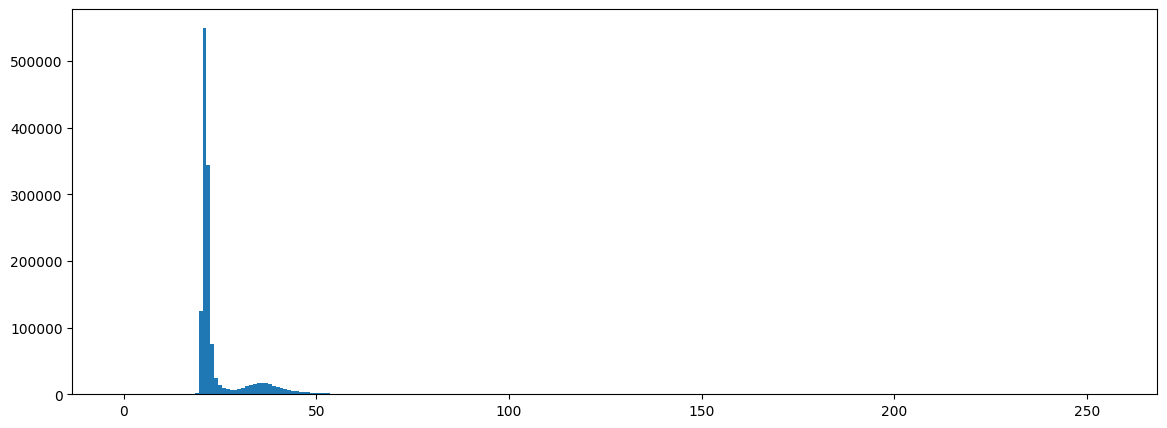

In [60]:
plt.figure(figsize=(14,5))
plt.bar(range(256), h, width=1)

**[Task 1.4.]()** Implement the method of Otsu:

In [61]:

Otzu = np.zeros(256)
for T in range(0, 255): 
     n = img8[img8 < T]
     m = img8[img8 >= T]
     if len(n) == 0 or len(m) == 0:
          continue
     Otzu[T] = len(n) * np.var(n) + len(m) * np.var(m)

print(n)
print(m)
To = np.argmin(Otzu)
print(To)

[37 39 38 ... 24 24 23]
[]
0


In [62]:
Otzu =  np.full(256, np.inf)  #muss inf sein sonst ist null der beste wert
for T in range(1, 256): 
     n = img8[img8 < T]
     m = img8[img8 >= T]
     if len(n) == 0 or len(m) == 0: #wert wird nicht überschrieben
          continue
     Otzu[T] = len(n) * np.var(n) + len(m) * np.var(m)

print(Otzu)
To = np.argmin(Otzu)
print(To)

[              inf               inf               inf               inf
               inf               inf               inf               inf
               inf               inf               inf               inf
               inf               inf               inf               inf
               inf               inf               inf 62268423.49896929
 62231302.67756923 59818223.62454262 47165648.8532488  27449150.57824366
 18586354.36935248 15253989.89752736 13539656.28011815 12557445.78895864
 11933561.89796724 11536254.18924297 11313729.00229155 11275653.93934225
 11495860.3303481  12094366.78891711 13176916.55272644 14767374.26909976
 16902177.86318459 19466392.13648611 22316940.04301708 25216024.01878978
 28108330.89532448 30810951.55526169 33287950.23202944 35560795.16565558
 37671210.81379128 39656813.25915194 41533993.49633765 43351146.15318058
 45045719.27117067 46595703.72321466 48078570.11368066 49403191.17985921
 50631766.83684008 51670386.54452664 52624546.35408

**[Task 1.5.]()** Perform Otsu thresholding:

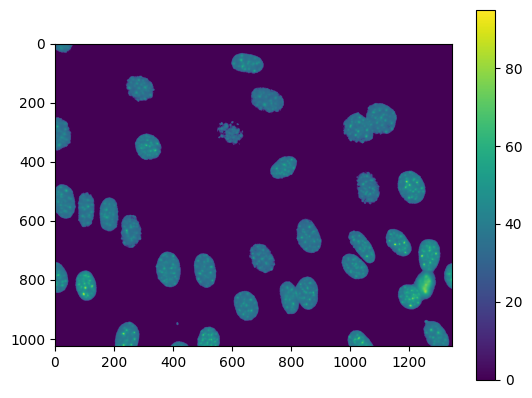

In [63]:
img_new = img8.copy()
img_new[img8 < To] = 0

plt.figure()
plt.imshow(img_new)
plt.colorbar()
#plt.imshow(img8)


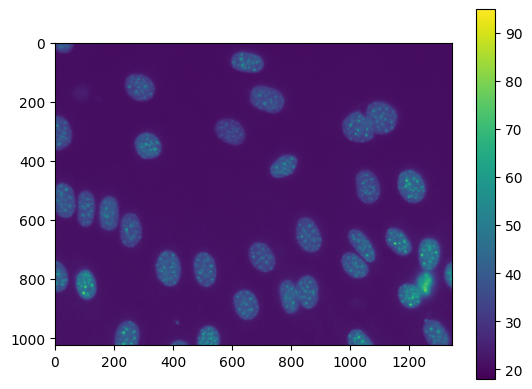

In [64]:
plt.imshow(img8)
plt.colorbar()

**[Task 1.6.]()** Compute the Dice coefficient:

In [66]:
G = img8
H = img_new

Dice_c = 2* (G*H).sum() / (G.sum() + H.sum())
print(Dice_c)

1.193436604037966
